In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 1. IMPORT CSV USING PANDAS
df = pd.read_csv(r"C:\Users\Manju M\Downloads\social_media_engagement_5000.csv")

In [ ]:
print(df.head())

In [ ]:
# Check current data types of all columns
print(df.dtypes)

In [ ]:
print(df.info())

In [ ]:
# 3. Convert Date Columns to Datetime
# Replace 'Date' with the exact name of the date column in your dataset
df["posted_at"] = pd.to_datetime(df["posted_at"])


In [ ]:
print("\n--- Data Types After Datetime Conversion ---")
print(df.dtypes)

In [ ]:
# 4. Use NumPy Arrays for Basic Array Operations
# Convert a target pandas series (e.g., engagement metrics) into a NumPy array
engagement_array = df["likes"].to_numpy()


In [ ]:
# Perform basic NumPy array operations
array_mean = np.mean(engagement_array)
array_sum = np.sum(engagement_array)
array_scaled = engagement_array * 1.10  # Simulating a 10% metric boost

In [ ]:
print("\n--- NumPy Array Basic Operations ---")
print(f"Mean Engagement: {array_mean}")
print(f"Total Engagement Summary: {array_sum}")
print(f"First 5 scaled elements: {array_scaled[:5]}")

In [ ]:
# Check missing values per column
print(df.isnull().sum())


In [ ]:
# Check total duplicate rows
print("Duplicates count:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

In [ ]:
# Standardize text columns (example: gender or category)
# df['gender'] = df['gender'].astype(str).str.lower().str.strip()

# Replace negative or impossible engagement counts with NaN or 0
metrics = ['likes', 'comments', 'shares']
for col in metrics:
  if col in df.columns:
    df.loc[df[col] < 0, col] = 0

In [ ]:
# Extract hashtag count from caption/text column (assuming a column like 'captions' or 'text')
if 'captions' in df.columns:
  df['hashtag_count'] = (
      df['captions'].fillna('').str.count(r'#\w+')
  )

# Clean and standardize sentiment labels
if 'sentiment' in df.columns:
  df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()

In [ ]:
df.to_csv("cleaned_social_media_engagement.csv", index=False)

In [ ]:
print("=== HEAD ===")
print(df.head())


In [ ]:
print("\n=== TAIL ===")
print(df.tail())

In [ ]:
print("\n=== SHAPE ===")
print(df.shape)


In [ ]:
print("\n=== COLUMNS ===")
print(df.columns.tolist())


In [ ]:
print("\n=== INFO ===")
df.info()

In [ ]:
print("\n=== DTYPES ===")
print(df.dtypes)

In [ ]:
print("\n=== DESCRIBE ===")
print(df.describe(include="all"))


In [ ]:
print("\n=== CATEGORICAL DISTRIBUTIONS ===")
for col in df.select_dtypes(include=["object", "category"]).columns:
  print(f"\n--- {col} (nunique: {df[col].nunique()}) ---")
  print(df[col].value_counts())
  print("Unique values:", df[col].unique())

In [ ]:
print("\n=== CORRELATION MATRIX (NUMERIC) ===")
corr_matrix = df.select_dtypes(include=[np.number]).corr()
print(corr_matrix)


In [ ]:
print("\n=== GROUPBY SUMMARIES ===")
if "post_type" in df.columns and "likes" in df.columns:
  print(df.groupby("post_type")["likes"].mean())
if "country" in df.columns and "impressions" in df.columns:
  print(df.groupby("country")["impressions"].mean())


In [ ]:
# Create new fields
if {"likes", "comments", "shares"}.issubset(df.columns):
  df["engagement_score"] = df["likes"] + (df["comments"] * 2) + (df["shares"] * 3)

In [ ]:
#Log-transformed metrics (optional)
numeric_cols_to_log = ["likes", "impressions", "followers"]
for col in numeric_cols_to_log:
  if col in df.columns:
    df[f"log_{col}"] = np.log1p(df[col])

In [ ]:
#Hashtag count (if caption/hashtags column exists)
if "hashtags" in df.columns:
  df["hashtag_count"] = df["hashtags"].astype(str).apply(lambda x: len(x.split()))


In [ ]:
# Perform groupby summaries by post_type, country, and sentiment
group_cols = [
    col
    for col in ["post_type", "country", "sentiment"]
    if col in df.columns
]
if group_cols:
  print("\n=== GROUPBY BY POST_TYPE, COUNTRY, SENTIMENT ===")
  print(df.groupby(group_cols).mean(numeric_only=True))

In [ ]:
# Task 5: Statistical Analysis
from scipy import stats
stats_targets = [
    c
    for c in [
        "likes",
        "comments",
        "shares",
        "watch_time",
        "engagement_rate",
        "followers",
    ]
    if c in df.columns
]

stats_list = []
for col in stats_targets:
  s = df[col].dropna()
  mean_val = s.mean()
  median_val = s.median()
  mode_val = s.mode().iloc[0] if not s.mode().empty else np.nan
  std_val = s.std()
  var_val = s.var()
  p25, p50, p75, p90 = np.percentile(s, [25, 50, 75, 90])
  skew_val = stats.skew(s)
  kurt_val = stats.kurtosis(s)
  stats_list.append({
      "feature": col,
      "mean": mean_val,
      "median": median_val,
      "mode": mode_val,
      "std": std_val,
      "variance": var_val,
      "p25": p25,
      "p50": p50,
      "p75": p75,
      "p90": p90,
      "skewness": skew_val,
      "kurtosis": kurt_val,
  })

stats_df = pd.DataFrame(stats_list)
print("\n=== STATISTICAL ANALYSIS TABLE ===")
print(stats_df)



In [ ]:
# Task 6: Data Visualization (Min. 8+ Plots)
sns.set_theme(style="whitegrid")


In [ ]:
# Matplotlib (1-6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
if "likes" in df.columns and "impressions" in df.columns:
  axes[0, 0].scatter(df["impressions"], df["likes"], alpha=0.5)
  axes[0, 0].set_title("Scatter: Likes vs Impressions")
if "date" in df.columns and "engagement_rate" in df.columns:
  daily_eng = df.groupby("date")["engagement_rate"].mean()
  axes[0, 1].plot(daily_eng.index, daily_eng.values)
  axes[0, 1].set_title("Line: Daily Engagement Trend")

if "category" in df.columns:
  df["category"].value_counts().plot(kind="bar", ax=axes[0, 2])
  axes[0, 2].set_title("Bar: Posts by Category")

if "gender" in df.columns:
  df["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 0])
  axes[1, 0].set_title("Pie: Gender Distribution")

if "age" in df.columns:
  axes[1, 1].hist(df["age"].dropna(), bins=20, edgecolor="black")
  axes[1, 1].set_title("Histogram: Age")

if "engagement_rate" in df.columns:
  axes[1, 2].boxplot(df["engagement_rate"].dropna())
  axes[1, 2].set_title("Box: Engagement Rate")

plt.tight_layout()
plt.show()


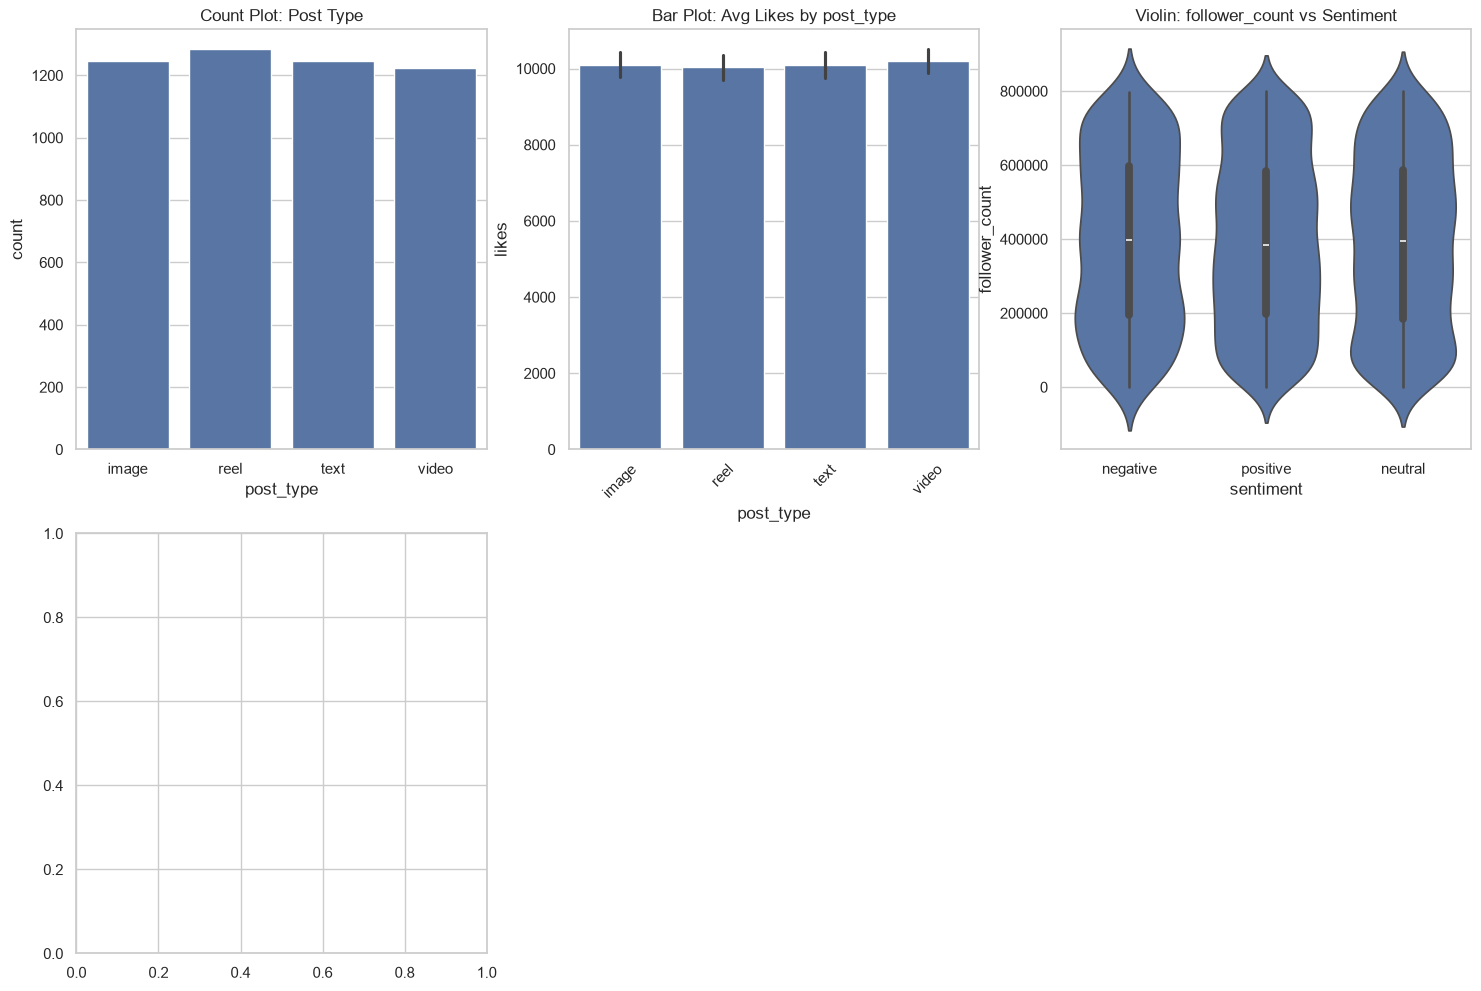


KeyboardInterrupt


KeyboardInterrupt



In [ ]:
# Seaborn (7-12)
plt.figure(figsize=(18, 12))
plt.subplot(2, 3, 1)
sns.countplot(data=df, x="post_type")
plt.title("Count Plot: Post Type")

plt.subplot(2, 3, 2)
sns.barplot(data=df, x="post_type", y="likes")
plt.title("Bar Plot: Avg Likes by post_type")
plt.xticks(rotation=45)

if {"follower_count", "sentiment"}.issubset(df.columns):
  plt.subplot(2, 3, 3)
  sns.violinplot(data=df, x="sentiment", y="follower_count")
  plt.title("Violin: follower_count vs Sentiment")

plt.subplot(2, 3, 4)
sns.pairplot(df.select_dtypes(include=[np.number]))
plt.title("Pair Plot: Numeric Features")

plt.subplot(2, 3, 5)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Heatmap: Correlation Matrix")

if {"engagement_rate", "device_type"}.issubset(df.columns):
  plt.subplot(2, 3, 6)
  sns.swarmplot(data=df, x="device_type", y="engagement_rate")
  plt.title("Swarm Plot: Engagement vs Device")

plt.tight_layout()
plt.show()

In [ ]:
# Plotly Interactive
if {"impression_count", "likes", "post_type"}.issubset(df.columns):
  fig_plotly = px.scatter(
      df,
      x="impression_count",
      y="likes",
      color="post_type",
      size="engagement_score" if "engagement_score" in df.columns else None,
      hover_data=df.columns,
      title="Interactive Scatter: Likes vs Impressions",
  )
  fig_plotly.show()